In [18]:
import yfinance as yf
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint, adfuller
import datetime as dt


In [ ]:
LOOKBACK = 100
ENTRY_THRESHOLD = 1.5
EXIT_THRESHOLD = 0.5
P_THRESHOLD = 0.05
TRAINING_START = dt.datetime(2020-1-1)
TEST_START = dt.datetime(2025-1-1)
TEST_END = dt.datetime(2026-11-1)

TypeError: function missing required argument 'month' (pos 2)

Pull V and MA info from yfinance module, check data for cleanliness

In [ ]:
tickers = ["MA", "V"]

df = yf.download(tickers, start="2020-01-01", end="2026-11-01", auto_adjust=True)

prices = yf.download(tickers, start="2020-01-01", end="2026-11-01")["Close"]

# long_df = (
#     df.stack(level=1, future_stack=True)
#       .rename_axis(["Date", "Ticker"])
#       .reset_index()
# )
df.columns = [f"{ticker} {field}" for field, ticker in df.columns]

display(df.head())
# display(long_df.head())
display(prices.head())

print(prices.isna().sum())
print(prices.index.min(), prices.index.max())
print(prices.shape)

[*********************100%***********************]  2 of 2 completed
[*********************100%***********************]  2 of 2 completed


,MA Close,V Close,MA High,V High,MA Low,V Low,MA Open,V Open,MA Volume,V Volume
Date,,,,,,,,,,
2020-01-02,291.464813,181.756363,291.599295,181.775387,287.727701,179.473953,288.649959,179.740234,3272400,8733000
2020-01-03,288.621185,180.310837,290.532986,181.604206,286.863129,178.713138,287.689311,179.179137,2501300,4899700
2020-01-06,289.389709,179.920929,289.485755,179.939953,284.384475,177.990387,285.671801,178.789229,3307200,10109500
2020-01-07,288.409851,179.445419,291.455263,180.786342,288.092835,179.359832,289.879711,180.301319,3182000,4392300
2020-01-08,293.498749,182.517151,295.278409,183.068736,289.083284,179.550015,289.343007,180.206212,3224400,5712000


Ticker,MA,V
Date,,
2020-01-02,291.464813,181.756363
2020-01-03,288.621185,180.310837
2020-01-06,289.389709,179.920929
2020-01-07,288.409851,179.445419
2020-01-08,293.498749,182.517151


Ticker
MA    0
V     0
dtype: int64
2020-01-02 00:00:00 2026-10-30 00:00:00
(1717, 2)


Three DataFrames:  
1. `df` Shows Close, High, Low, Open, and Volume for MA and V over time  
2. `long_df` uses stack to seperate the ticker headers into a column  
3. `prices` shows the close price of V and MA over time

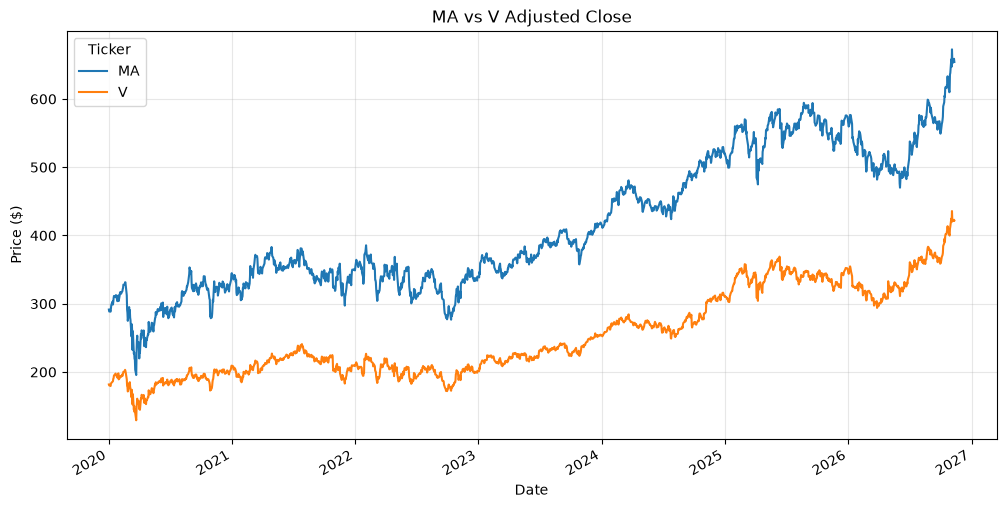

In [ ]:
prices.plot(figsize=(12, 6), title="MA vs V Adjusted Close")
plt.ylabel("Price ($)")
plt.grid(alpha=0.3)
plt.show()

Normalize prices because MA trades higher than V for visualization

Ticker,MA,V
Date,,
2020-01-02,1.000000,1.000000
2020-01-03,0.990244,0.992047
2020-01-06,0.992881,0.989902
2020-01-07,0.989518,0.987286
2020-01-08,1.006978,1.004186


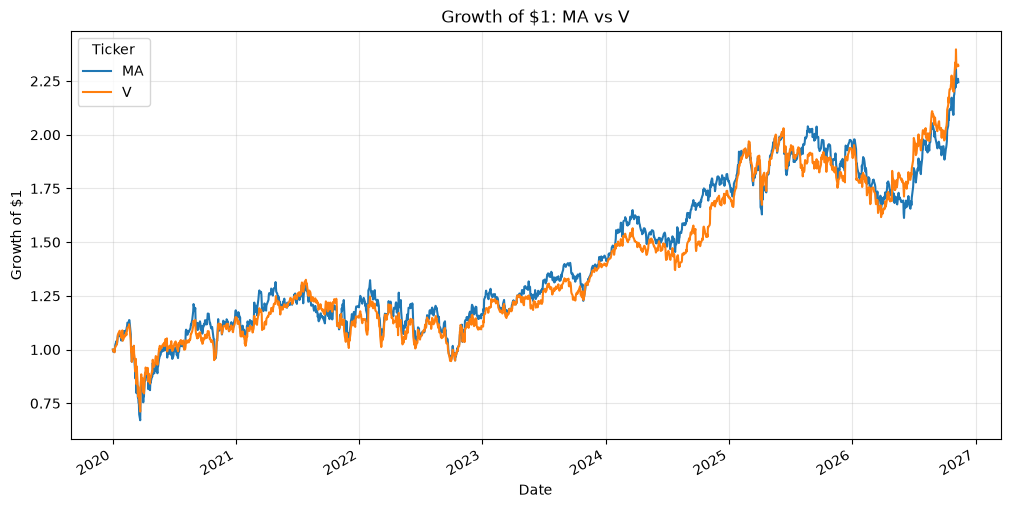

In [ ]:
norm = prices / prices.iloc[0]
display(norm.head())

norm.plot(figsize=(12, 6), title="Growth of $1: MA vs V")
plt.ylabel("Growth of $1")
plt.grid(alpha=0.3)
plt.show()

get log prices using numpy make comparison easier, if both stocks increase by 5%, log price will increase by the same amount, this will be used for our cointegration approach  
`coint()` from the `statsmodels` module tests for cointegration, if the p-value is lower than 0.05, cointegration is suggested  
`coint()` regresses Y on X, so checking both directions for sanity

Ticker,MA,V
Date,,
2020-01-02,5.674919,5.202667
2020-01-03,5.665115,5.194682
2020-01-06,5.667774,5.192517
2020-01-07,5.664383,5.189871
2020-01-08,5.681873,5.206844
...,...,...
2026-10-26,6.419180,5.999962
2026-10-27,6.413213,5.994254
2026-10-28,6.413967,5.991114


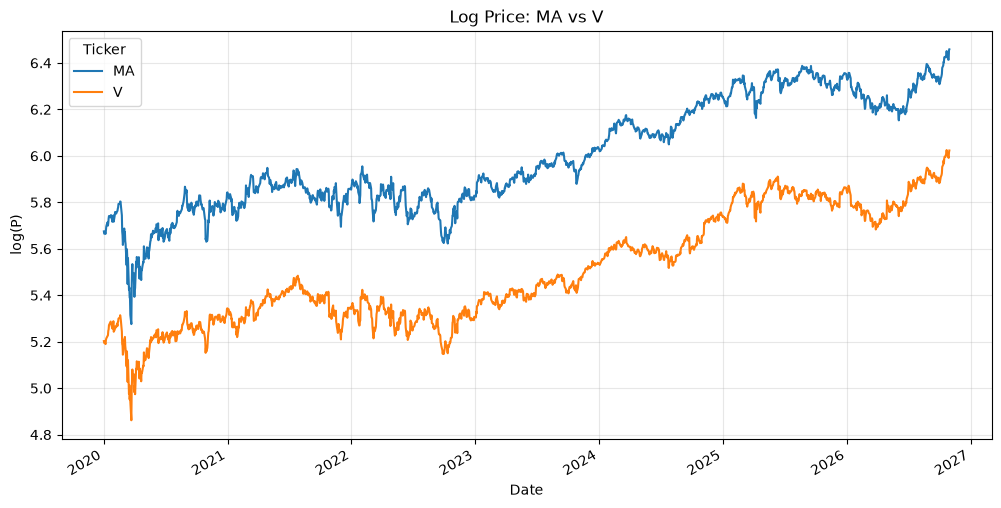

In [24]:
log_p = np.log(prices)
display(log_p)

log_p.plot(figsize=(12, 6), title="Log Price: MA vs V")
plt.ylabel("log(P)")
plt.grid(alpha=0.3)
plt.show()


In [23]:
score, pvalue, _ = coint(log_p["MA"], log_p["V"])
print(f"Engle-Granger p-value: {pvalue:.4f}")

score, pvalue, _ = coint(log_p["V"], log_p["MA"])
print(f"Engle-Granger p-value: {pvalue:.4f}")

Engle-Granger p-value: 0.0153
Engle-Granger p-value: 0.0232


,0
Date,
2020-01-02,0.472252
2020-01-03,0.470433
2020-01-06,0.475257
2020-01-07,0.474511
2020-01-08,0.475029
...,...
2026-10-26,0.419219
2026-10-27,0.418959
2026-10-28,0.422853


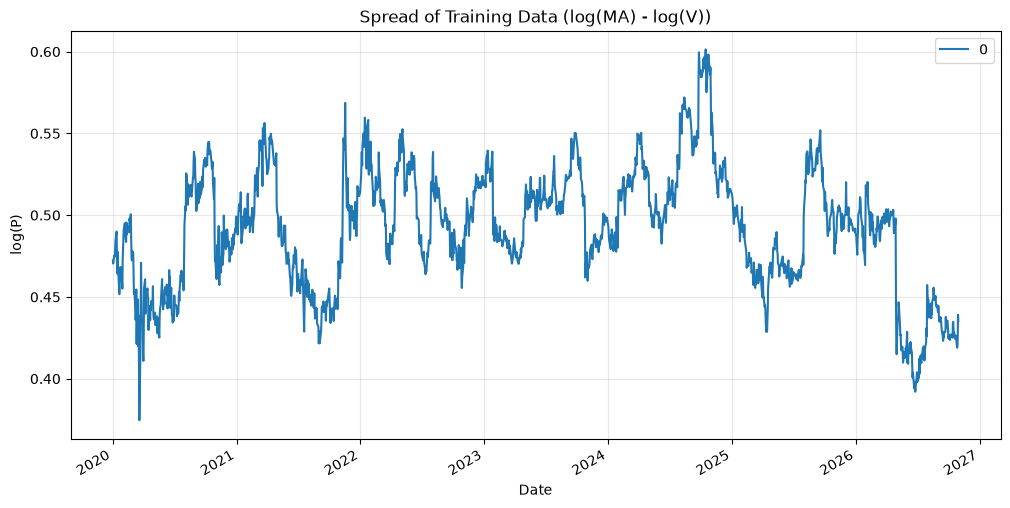

In [28]:
training_spread = pd.DataFrame(log_p['MA'] - log_p['V']) 
display(training_spread)

training_spread.plot(figsize=(12, 6), title="Spread of Training Data (log(MA) - log(V))")
plt.ylabel("log(P)")
plt.grid(alpha=0.3)
plt.show()

`adfuller()` checks if a time series is stationary (mean, variance, autocorrelation are constant)  


ADF F-Statistic: -3.716810633375483
ADF p (train spread): 0.00388281581633872
spread level std: 0.03024950785655182
spread daily change std: 0.008507174610609843


/var/folders/w_/l65c0y6d4lj7syg13x91lbp40000gn/T/ipykernel_50449/440829935.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("ADF F-Statistic:", adfuller(spread_train)[0])
/var/folders/w_/l65c0y6d4lj7syg13x91lbp40000gn/T/ipykernel_50449/440829935.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("ADF p (train spread):", adfuller(spread_train)[1])


Half-life: 17.52 days
